# 03 — Calidad de señal

**Etapa I (PPS) / F2.** Muestreo determinista: 3 ventanas de 10 s por registro, 12 derivaciones
superficiales (por nombre, no por índice). Métricas por ventana:

- `deriva_rms_mV`: RMS de la componente < 0.5 Hz (filtro de media móvil de 2 s) → deriva basal.
- `ruido_hf_rms_mV`: RMS de la componente > 100 Hz → ruido de alta frecuencia.
- `red_ratio`: P(49–51 Hz) / P(1–200 Hz) del PSD (Welch) → interferencia de red (AP-8).
- `flat_frac`: fracción de muestras consecutivas idénticas → saturación/clipping (AP-9).

Insumo directo del diseño de filtros (F4) y del riesgo RS1.

In [1]:
%matplotlib inline
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(os.environ.get('PROJECT_ROOT',
                           Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
RES = ROOT / 'results'
FIG = RES / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(2026)

import wfdb
from scipy import signal

DATA = ROOT / 'data' / ('leipzig-heart-center-ecg-database-arrhythmias-in-children-'
                        'and-patients-with-congenital-heart-disease-1.0.0')
SURFACE = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
W_S, N_VENT = 10, 3


def leer_ventana(name, ini):
    h = wfdb.rdheader(str(DATA / name))
    ch = [h.sig_name.index(s) for s in SURFACE]
    ini = int(np.clip(ini, 0, h.sig_len - W_S * h.fs))
    r = wfdb.rdrecord(str(DATA / name), sampfrom=ini, sampto=ini + W_S * h.fs, channels=ch, physical=True)
    return r.p_signal, r.fs, r.units[0]


def metricas(x, fs):
    base = x - pd.DataFrame(x).rolling(int(2 * fs), center=True, min_periods=1).mean().values
    sos = signal.butter(4, 100, 'hp', fs=fs, output='sos')
    hf = signal.sosfiltfilt(sos, x, axis=0)
    f, p = signal.welch(x, fs=fs, nperseg=2048, axis=0)
    pm = p.mean(axis=1)
    banda = (f >= 1) & (f <= 200)
    red = pm[(f >= 49) & (f <= 51)].sum() / pm[banda].sum()
    flat = np.mean(np.diff(x, axis=0) == 0, axis=0).mean()
    return (np.sqrt((base ** 2).mean()), np.sqrt((hf ** 2).mean()), red, flat)


records = [r.strip() for r in (DATA / 'RECORDS').read_text().splitlines() if r.strip()]
filas = []
for name in records:
    h = wfdb.rdheader(str(DATA / name))
    for ini in rng.integers(0, h.sig_len - W_S * h.fs, N_VENT):
        x, fs, unidad = leer_ventana(name, ini)
        d, r, red, flat = metricas(x, fs)
        filas.append({'registro': name, 'deriva_rms': d, 'ruido_hf_rms': r, 'red_ratio': red, 'flat_frac': flat})
calidad = pd.DataFrame(filas).groupby('registro', as_index=False).median().round(5)
calidad.to_csv(RES / 'inventario' / 'calidad_senal.csv', index=False)
calidad.describe().round(4)


,deriva_rms,ruido_hf_rms,red_ratio,flat_frac
count,39.0000,39.0000,39.0000,39.0000
mean,0.2732,0.0099,0.0001,0.3100
std,0.0989,0.0144,0.0000,0.0574
min,0.1259,0.0028,0.0000,0.2076
25%,0.2013,0.0038,0.0000,0.2644
50%,0.2568,0.0048,0.0000,0.3040
75%,0.3411,0.0073,0.0001,0.3560
max,0.5054,0.0865,0.0002,0.4257


In [2]:
reg = pd.read_csv(RES / 'inventario' / 'registros.csv')
cal = calidad.merge(reg[['registro', 'grupo', 'anot_calidad']], on='registro')
print('Peores 5 por deriva:');  display(cal.nlargest(5, 'deriva_rms')[['registro', 'grupo', 'deriva_rms']])
print('Peores 5 por red 50 Hz:'); display(cal.nlargest(5, 'red_ratio')[['registro', 'grupo', 'red_ratio']])
print('Peores 5 por flat:');    display(cal.nlargest(5, 'flat_frac')[['registro', 'grupo', 'flat_frac']])
print('Correlación anot_calidad vs métricas:')
display(cal[['anot_calidad', 'deriva_rms', 'ruido_hf_rms', 'red_ratio', 'flat_frac']].corr()['anot_calidad'].round(2))


Peores 5 por deriva:


,registro,grupo,deriva_rms
21,x0029,pediatrico,0.50542
9,x0018,pediatrico,0.45775
2,x0011,pediatrico,0.44511
28,x009,pediatrico,0.42792
38,x109,adulto,0.41383


Peores 5 por red 50 Hz:


,registro,grupo,red_ratio
34,x105,adulto,0.00016
13,x0021,pediatrico,0.00013
25,x006,pediatrico,0.00011
3,x0012,pediatrico,0.00009
8,x0017,pediatrico,0.00009


Peores 5 por flat:


,registro,grupo,flat_frac
29,x100,adulto,0.42570
30,x101,adulto,0.41408
31,x102,adulto,0.38950
35,x106,adulto,0.37930
38,x109,adulto,0.37718


Correlación anot_calidad vs métricas:


anot_calidad    1.00
deriva_rms     -0.04
ruido_hf_rms    0.07
red_ratio      -0.04
flat_frac      -0.12
Name: anot_calidad, dtype: float64

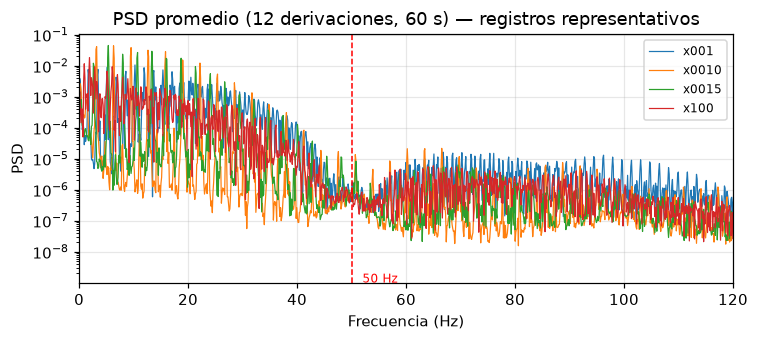

In [3]:
reps = ['x001', 'x0010', 'x0015', 'x100']
fig, ax = plt.subplots(figsize=(7, 3.2))
for name in reps:
    ini = int(rng.integers(0, wfdb.rdheader(str(DATA / name)).sig_len - 60 * 977))
    x, fs, _ = leer_ventana(name, ini)
    x = x[: 60 * fs]
    f, p = signal.welch(x, fs=fs, nperseg=8192, axis=0)
    ax.semilogy(f, p.mean(axis=1), lw=0.8, label=name)
ax.axvline(50, color='red', ls='--', lw=1); ax.text(52, ax.get_ylim()[0], '50 Hz', color='red', fontsize=8)
ax.set_xlim(0, 120); ax.set_xlabel('Frecuencia (Hz)'); ax.set_ylabel('PSD')
ax.set_title('PSD promedio (12 derivaciones, 60 s) — registros representativos')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '03_psd_representativos.png'); plt.show()


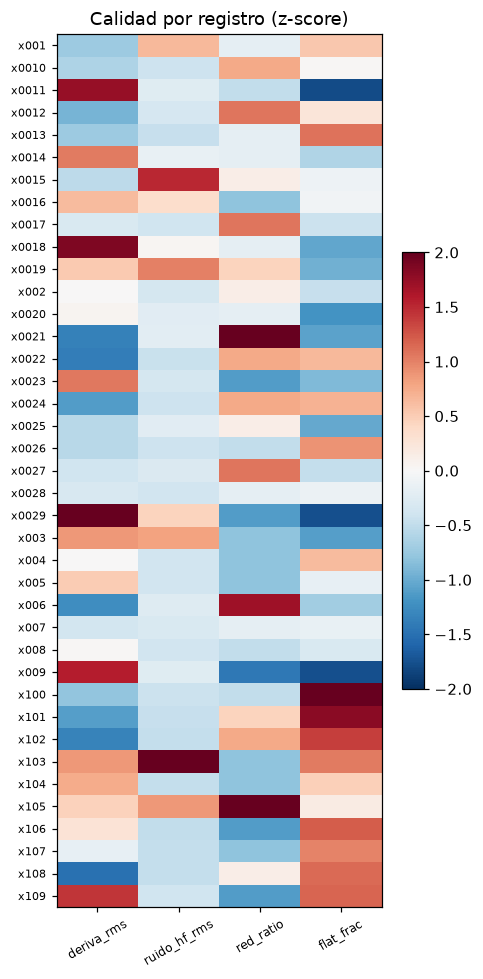

In [4]:
mat = cal.set_index('registro')[['deriva_rms', 'ruido_hf_rms', 'red_ratio', 'flat_frac']]
z = (mat - mat.mean()) / mat.std()
fig, ax = plt.subplots(figsize=(4.5, 9))
im = ax.imshow(z.values, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
ax.set_yticks(range(len(z)), z.index, fontsize=7); ax.set_xticks(range(4), z.columns, rotation=30, fontsize=8)
ax.grid(False); ax.set_title('Calidad por registro (z-score)')
fig.colorbar(im, ax=ax, shrink=0.5)
fig.tight_layout(); fig.savefig(FIG / '03_heatmap_calidad.png'); plt.show()


## Conclusiones

- **Interferencia de red (AP-8): confirmada y heterogénea.** El PSD muestra un pico
  estrecho a 50 Hz en 3 de 4 registros representativos; en `x001` sobresale ~6 órdenes
  de magnitud sobre el piso espectral, en `x100` no es visible. El notch IIR 50 Hz del
  acta (RF2) queda justificado, y su diseño debe considerar registros con contaminación
  muy distinta entre sí.
- La energía del ECG se concentra por debajo de ~40 Hz, lo que respalda un corte
  paso-bajo conservador (a definir en F4, considerando espículas de marcapasos).
- Los peores registros por deriva basal, ruido HF y `flat_frac` quedan tabulados arriba;
  las anotaciones `~` (AP-6) se contrastan contra estas métricas en la celda de
  correlación para decidir exclusiones de ventanas en entrenamiento.